**Fundamentos de Databricks / Hover Andres Duque**

**1. Creación del entorno**

In [0]:
%sql
CREATE CATALOG IF NOT EXISTS analitica

**1.1 Creación del esquema de nuestro catalogo**

In [0]:
%sql
CREATE SCHEMA IF NOT EXISTS data;
USE SCHEMA data;


**1.2 Creación del volumen**

In [0]:
%sql
CREATE VOLUME IF NOT EXISTS analitica.data.landing

**2. Creación de tablas con SQL**

In [0]:
%sql
USE analitica.data

In [0]:
%sql
CREATE OR REPLACE TABLE tabla_simple (
    id INT,
    nombre STRING
    )
USING DELTA

**2.1 Inserta Datos a Tabla**

In [0]:
%sql
INSERT INTO tabla_simple VALUES (1, 'Ana'), (2, 'Luis'), (3, 'María')

num_affected_rows,num_inserted_rows
3,3


In [0]:
%sql
SELECT * FROM tabla_simple

id,nombre
1,Ana
2,Luis
3,María


3. Funciones de PySpark

In [0]:
from pyspark.sql import functions as F

In [0]:
%sql
CREATE OR REPLACE FUNCTION analitica.data.fn_mayor_que_10(x DOUBLE)
RETURN X > 10;

In [0]:
%sql
SELECT * FROM tabla_simple
WHERE analitica.data.fn_mayor_que_10(11)

id,nombre
1,Ana
2,Luis
3,María


**4. Lectura de datos**

In [0]:
path_data_demo = "/Volumes/analitica/data/landing/data_demo.csv"

df = spark.read.csv(
    path=path_data_demo,
    header=True,
    inferSchema=True
)
display(df.limit(10))

rooms,garages,useful_area,value,interior_quality,time_on_market,has_outlier
3.0,1.0,105.0,1038640.0,2,31.7870789438591,0
3.0,2.0,76.0,606405.0,4,209.46884172046086,0
3.0,1.0,123.0,1534500.0,1,38.0,0
3.0,2.0,180.0,1131950.0,5,154.0,0
3.0,1.0,67.0,452672.0,4,15.0,0
3.0,3.0,198.0,3116290.0,3,306.3557294709182,0
4.0,2.0,245.0,1202560.0,3,24.824464122611424,0
2.0,2.0,66.0,419282.0,5,24.0,0
2.0,1.0,114.0,1830260.0,1,251.39533835163672,0
2.0,1.0,56.0,274005.0,5,93.0,0


**4.1 Guardar Tablas**

In [0]:
df.write.format("delta").mode("overwrite").saveAsTable("inmuebles")

In [0]:
%sql
SELECT * FROM inmuebles LIMIT 10

rooms,garages,useful_area,value,interior_quality,time_on_market,has_outlier
3.0,1.0,105.0,1038640.0,2,31.7870789438591,0
3.0,2.0,76.0,606405.0,4,209.46884172046086,0
3.0,1.0,123.0,1534500.0,1,38.0,0
3.0,2.0,180.0,1131950.0,5,154.0,0
3.0,1.0,67.0,452672.0,4,15.0,0
3.0,3.0,198.0,3116290.0,3,306.3557294709182,0
4.0,2.0,245.0,1202560.0,3,24.824464122611424,0
2.0,2.0,66.0,419282.0,5,24.0,0
2.0,1.0,114.0,1830260.0,1,251.39533835163672,0
2.0,1.0,56.0,274005.0,5,93.0,0


5. Lectura de Pedidos

In [0]:
path_data_demo = "/Volumes/analitica/data/landing/spark_intro.csv"

df_pedidos = spark.read.csv(
    path=path_data_demo,
    header=True,
    inferSchema=True
)


In [0]:
display(df_pedidos)

order_id,order_date,country,product,category,units_sold,unit_price
1,2024-01-02,Spain,Laptop,Electronics,2,1200
2,2024-01-03,Spain,Mouse,Accessories,5,25
3,2024-01-05,France,Laptop,Electronics,1,1150
4,2024-01-06,Germany,Keyboard,Accessories,3,45
5,2024-01-07,Spain,Monitor,Electronics,2,300
6,2024-01-08,France,Mouse,Accessories,10,23
7,2024-01-10,Germany,Laptop,Electronics,1,1300
8,2024-01-11,Spain,Keyboard,Accessories,4,42
9,2024-01-12,France,Monitor,Electronics,1,280
10,2024-01-14,Germany,Mouse,Accessories,6,27


**5.1 Selección y filtro**

In [0]:
from pyspark.sql import functions as F

In [0]:
display(
    df_pedidos.select("order_id", "country", "product", "units_sold")
    .filter(F.col("country") == "Spain")
)
  

order_id,country,product,units_sold
1,Spain,Laptop,2
2,Spain,Mouse,5
5,Spain,Monitor,2
8,Spain,Keyboard,4


5.2 Columna Calcula

In [0]:
from pyspark.sql import functions as F

df_importes = df_pedidos.withColumn(
    "importe", F.col("units_sold") * F.col("unit_price")
)

display(df_importes)

order_id,order_date,country,product,category,units_sold,unit_price,importe
1,2024-01-02,Spain,Laptop,Electronics,2,1200,2400
2,2024-01-03,Spain,Mouse,Accessories,5,25,125
3,2024-01-05,France,Laptop,Electronics,1,1150,1150
4,2024-01-06,Germany,Keyboard,Accessories,3,45,135
5,2024-01-07,Spain,Monitor,Electronics,2,300,600
6,2024-01-08,France,Mouse,Accessories,10,23,230
7,2024-01-10,Germany,Laptop,Electronics,1,1300,1300
8,2024-01-11,Spain,Keyboard,Accessories,4,42,168
9,2024-01-12,France,Monitor,Electronics,1,280,280
10,2024-01-14,Germany,Mouse,Accessories,6,27,162


**5.3 Agrupación**

In [0]:
resumen_pais = df_importes.groupBy("country").agg(
    F.sum("units_sold").alias("unidades"),
    F.round(F.sum("importe"), 2).alias("importe_total")
)

display(resumen_pais.orderBy(F.desc("importe_total")))

country,unidades,importe_total
Spain,13,3293
France,12,1660
Germany,10,1597


6. **Lectura de la dimensión de pedidos**

In [0]:
path_data_demo = "/Volumes/analitica/data/landing/dim_spark_intro.csv"

df_productos = spark.read.csv(
    path=path_data_demo,
    header=True,
    schema="product STRING, product_family STRING, supplier STRING",
    mode="FAILFAST"
)


**6.1 Union sencilla**

In [0]:
display(df_productos.groupBy("product").count().filter("count > 1"))

product,count


In [0]:
df_enriquecido = df_importes.join(df_productos, "product", "left")
display(df_enriquecido)

product,order_id,order_date,country,category,units_sold,unit_price,importe,product_family,supplier
Laptop,1,2024-01-02,Spain,Electronics,2,1200,2400,Computers,TechCorp
Mouse,2,2024-01-03,Spain,Accessories,5,25,125,Peripherals,InputMakers
Laptop,3,2024-01-05,France,Electronics,1,1150,1150,Computers,TechCorp
Keyboard,4,2024-01-06,Germany,Accessories,3,45,135,Peripherals,InputMakers
Monitor,5,2024-01-07,Spain,Electronics,2,300,600,Displays,ScreenWorld
Mouse,6,2024-01-08,France,Accessories,10,23,230,Peripherals,InputMakers
Laptop,7,2024-01-10,Germany,Electronics,1,1300,1300,Computers,TechCorp
Keyboard,8,2024-01-11,Spain,Accessories,4,42,168,Peripherals,InputMakers
Monitor,9,2024-01-12,France,Electronics,1,280,280,Displays,ScreenWorld
Mouse,10,2024-01-14,Germany,Accessories,6,27,162,Peripherals,InputMakers


In [0]:
print("pedidos antes: ", df_pedidos.count())
print("pedidos despues: ", df_enriquecido.count())
display(df_enriquecido.count()== df_pedidos.count(),"revisar la llave por producto")

pedidos antes:  10
pedidos despues:  10


True

'revisar la llave por producto'

**Guardar tabla**

In [0]:
df_enriquecido.write.format("delta").mode("overwrite").saveAsTable("pedidos_enriquecidos")

**7. Lectura del ejemplo de ventas**

In [0]:
ruta = "/Volumes/analitica/data/landing"

# 1. Productos
df_productos = spark.read.csv(
    ruta + "/dim_spark_intro.csv",
    header=True,
    inferSchema=True
)

# 2. Ventas
df_ventas = spark.read.csv(
    ruta + "/ventas_2025.csv",
    header=True,
    schema="id INT, fecha DATE, producto STRING, cantidad INT, precio DOUBLE",
    dateFormat="yyyy-MM-dd",
    mode="FAILFAST"
)

display(df_ventas.limit(10))
df_ventas.printSchema()
print("Registros de venta:", df_ventas.count())

id,fecha,producto,cantidad,precio
1,2025-01-03,Teclado,20,25.99
2,2025-01-03,Webcam,1,39.99
3,2025-01-03,Auriculares,18,29.99
4,2025-01-04,Webcam,10,39.99
5,2025-01-04,Mouse,2,15.5
6,2025-01-05,Altavoces,13,45.0
7,2025-01-08,Teclado,11,25.99
8,2025-01-10,Auriculares,5,29.99
9,2025-01-11,Monitor,2,199.99
10,2025-01-12,Microfono,20,59.99


root
 |-- id: integer (nullable = true)
 |-- fecha: date (nullable = true)
 |-- producto: string (nullable = true)
 |-- cantidad: integer (nullable = true)
 |-- precio: double (nullable = true)

Registros de venta: 100


**7.1 EDA inicial**

In [0]:
display(df_ventas.groupBy("id").count().filter("count > 1"))

df_invalidos = df_ventas.filter(
    F.col("id").isNull() | F.col("fecha").isNull() |
    F.col("producto").isNull() | F.col("cantidad").isNull() |
    F.col("precio").isNull() | F.isnan("precio") |
    (F.col("cantidad") <= 0) | (F.col("precio") < 0)
)
display(df_invalidos)
assert df_invalidos.count() == 0, "Revisar los registros antes de continuar."

id,count


id,fecha,producto,cantidad,precio


In [0]:
df_ventas.write.format("delta").mode("overwrite").saveAsTable("ventas")


In [0]:
%sql
DESCRIBE DETAIL ventas

format,id,name,description,location,createdAt,lastModified,partitionColumns,clusteringColumns,numFiles,sizeInBytes,properties,minReaderVersion,minWriterVersion,tableFeatures,statistics,clusterByAuto
delta,a858a9cb-eb40-44c3-8e67-0a7d3e48fdad,analitica.data.ventas,null,,2026-10-17T20:20:17.605Z,2026-10-24T03:13:02.000Z,List(),List(),1,2394,"Map(delta.parquet.compression.codec -> zstd, delta.parquet.format.version.afe.internal -> 2.12.0, delta.enableDeletionVectors -> true, delta.parquet.format.version -> 2.12.0, io.unitycatalog.tableId -> b7fa19d4-5993-48d7-abd8-6eaf3be9ebed)",3,7,"List(appendOnly, deletionVectors, invariants)","Map(numRowsDeletedByDeletionVectors -> 0, numDeletionVectors -> 0)",false


7.2 Consulta del importe por producto

In [0]:
%sql
SELECT producto,
       SUM(cantidad) AS unidades,
       ROUND(SUM(cantidad * precio), 2) AS importe_total
FROM ventas
GROUP BY producto
ORDER BY importe_total DESC

producto,unidades,importe_total
Monitor,64,12799.36
Impresora,85,7641.5
Altavoces,137,6165.0
Disco Duro,77,6159.23
Microfono,93,5579.07
Webcam,137,5478.63
Teclado,130,3378.7
Auriculares,92,2759.08
Mouse,88,1364.0
USB,99,989.01


Databricks visualization. Run in Databricks to view.

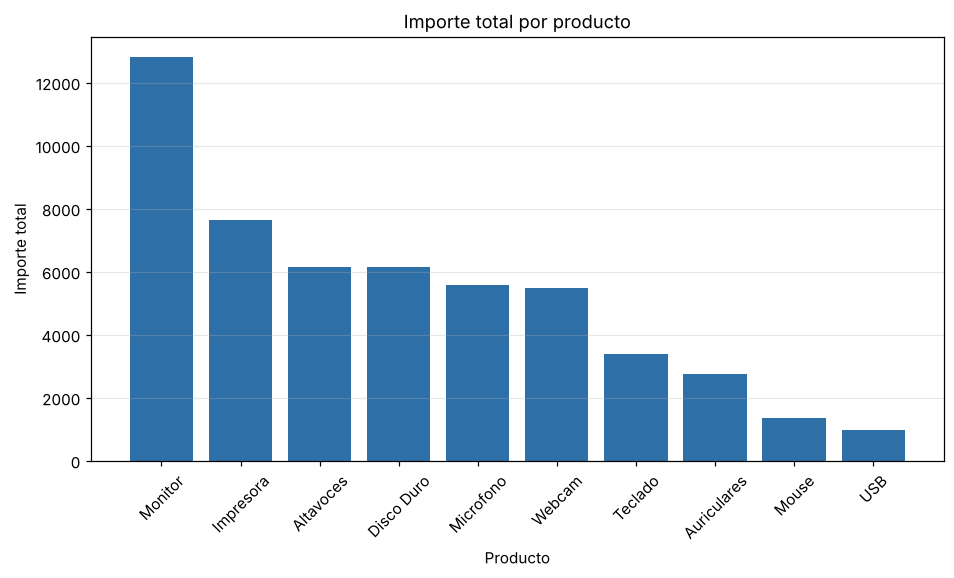

In [0]:
import matplotlib.pyplot as plt

pdf = spark.sql("""
    SELECT producto, ROUND(SUM(cantidad * precio), 2) AS importe_total
    FROM ventas
    GROUP BY producto
    ORDER BY importe_total DESC
""").toPandas()

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(pdf["producto"], pdf["importe_total"], color="#2E6FA7")
ax.set_title("Importe total por producto")
ax.set_xlabel("Producto")
ax.set_ylabel("Importe total")
ax.tick_params(axis="x", rotation=45)
ax.grid(axis="y", alpha=0.3)
plt.show()

**7.3Una variable para cambiar el filtro**

In [0]:
pais_elegido = "Spain"

display(df_enriquecido.filter(F.col("country") == pais_elegido))

product,order_id,order_date,country,category,units_sold,unit_price,importe,product_family,supplier
Laptop,1,2024-01-02,Spain,Electronics,2,1200,2400,Computers,TechCorp
Mouse,2,2024-01-03,Spain,Accessories,5,25,125,Peripherals,InputMakers
Monitor,5,2024-01-07,Spain,Electronics,2,300,600,Displays,ScreenWorld
Keyboard,8,2024-01-11,Spain,Accessories,4,42,168,Peripherals,InputMakers


**8. Copia de ensayo para Delta**

In [0]:
%sql
CREATE OR REPLACE TABLE ventas_delta_demo USING DELTA AS SELECT * FROM ventas

num_affected_rows,num_inserted_rows


**8.1 Versión de referencia**

In [0]:
historial = spark.sql("DESCRIBE HISTORY ventas_delta_demo")
version_inicial = historial.orderBy(F.desc("version")).first()["version"]

print("Versión de referencia:", version_inicial)

Versión de referencia: 6


**8.2 UPDATE**

In [0]:
%sql
UPDATE ventas_delta_demo SET precio = ROUND(precio + 1, 2) WHERE id = 1

num_affected_rows
1


In [0]:
%sql
SELECT * FROM ventas_delta_demo WHERE id = 1

id,fecha,producto,cantidad,precio
1,2025-01-03,Teclado,20,26.99


**8.3 INSERT**

In [0]:
%sql
INSERT INTO ventas_delta_demo VALUES (1001, DATE '2025-01-31', 'Producto demo', 2, 10.0)

num_affected_rows,num_inserted_rows
1,1


In [0]:
%sql
SELECT COUNT(*) AS registros FROM ventas_delta_demo

registros
101


**9. DELETE**

In [0]:
%sql
DELETE FROM ventas_delta_demo WHERE id = 1001

num_affected_rows
1


In [0]:
%sql
SELECT COUNT(*) AS registros FROM ventas_delta_demo

registros
100


**9.1 Fuente de cambios para MERGE**

In [0]:
%sql
CREATE OR REPLACE TEMP VIEW cambios_ventas AS
SELECT * FROM VALUES
  (1, DATE '2025-01-03', 'Teclado', 20, CAST(27.99 AS DOUBLE)),
  (1001, DATE '2025-01-31', 'Producto demo', 2, CAST(10.0 AS DOUBLE))
AS cambios(id, fecha, producto, cantidad, precio)

In [0]:
%sql
SELECT * FROM cambios_ventas

id,fecha,producto,cantidad,precio
1,2025-01-03,Teclado,20,27.99
1001,2025-01-31,Producto demo,2,10.0


**9.2 MERGE**

In [0]:
%sql
MERGE INTO ventas_delta_demo AS destino
USING cambios_ventas AS fuente
ON destino.id = fuente.id
WHEN MATCHED THEN UPDATE SET *
WHEN NOT MATCHED THEN INSERT *

num_affected_rows,num_updated_rows,num_deleted_rows,num_inserted_rows
2,1,0,1


In [0]:
%sql
SELECT * FROM ventas_delta_demo WHERE id IN (1, 1001) ORDER BY id

id,fecha,producto,cantidad,precio
1,2025-01-03,Teclado,20,27.99
1001,2025-01-31,Producto demo,2,10.0


**9.3 Historial**

In [0]:
%sql
DESCRIBE HISTORY ventas_delta_demo

version,timestamp,userId,userName,operation,operationParameters,job,notebook,queryHistoryStatementId,clusterId,readVersion,isolationLevel,isBlindAppend,operationMetrics,userMetadata,engineInfo
10,2026-10-24T03:13:38.000Z,72914905396047,andyduqueep@gmail.com,MERGE,"Map(predicate -> [""(id#13309 = id#13294)""], clusterBy -> [], matchedPredicates -> [{""actionType"":""update""}], statsOnLoad -> true, notMatchedBySourcePredicates -> [], notMatchedPredicates -> [{""actionType"":""insert""}])",null,List(246045475303445),d98cd4ed-3f79-47ae-9b09-027672c83917,1024-031124-i6vnrk8x-v2n,9,WriteSerializable,false,"Map(numTargetRowsCopied -> 0, numTargetRowsDeleted -> 0, numTargetFilesAdded -> 2, numTargetBytesAdded -> 3297, numTargetBytesRemoved -> 1662, numTargetDeletionVectorsAdded -> 0, numTargetRowsMatchedUpdated -> 1, executionTimeMs -> 4015, materializeSourceTimeMs -> 317, numTargetRowsInserted -> 1, numTargetRowsMatchedDeleted -> 0, numTargetDeletionVectorsUpdated -> 0, scanTimeMs -> 1908, numTargetRowsUpdated -> 1, numOutputRows -> 2, numTargetDeletionVectorsRemoved -> 0, numTargetRowsNotMatchedBySourceUpdated -> 0, numTargetChangeFilesAdded -> 0, numSourceRows -> 2, numTargetFilesRemoved -> 1, numTargetRowsNotMatchedBySourceDeleted -> 0, rewriteTimeMs -> 1707)",null,Databricks-Runtime/19.11.x-aarch64-photon-scala2.13
9,2026-10-24T03:13:29.000Z,72914905396047,andyduqueep@gmail.com,DELETE,"Map(predicate -> [""(id#12998 = 1001)""])",null,List(246045475303445),e1c19716-3bd8-4d69-81d1-8d9248405392,1024-031124-i6vnrk8x-v2n,8,WriteSerializable,false,"Map(numRemovedFiles -> 1, numRemovedBytes -> 1665, numCopiedRows -> 0, numDeletionVectorsAdded -> 0, numDeletionVectorsRemoved -> 0, numAddedChangeFiles -> 0, executionTimeMs -> 1351, numDeletionVectorsUpdated -> 0, numDeletedRows -> 1, scanTimeMs -> 1197, numAddedFiles -> 0, numAddedBytes -> 0, rewriteTimeMs -> 153)",null,Databricks-Runtime/19.11.x-aarch64-photon-scala2.13
8,2026-10-24T03:13:24.000Z,72914905396047,andyduqueep@gmail.com,WRITE,"Map(mode -> Append, statsOnLoad -> true, partitionBy -> [])",null,List(246045475303445),043a7c1e-7e43-4b61-a7ba-126e69ecbdca,1024-031124-i6vnrk8x-v2n,7,WriteSerializable,true,"Map(numFiles -> 1, numOutputRows -> 1, numOutputBytes -> 1665)",null,Databricks-Runtime/19.11.x-aarch64-photon-scala2.13
7,2026-10-24T03:13:20.000Z,72914905396047,andyduqueep@gmail.com,UPDATE,"Map(predicate -> [""(id#12196 = 1)""])",null,List(246045475303445),983c83dd-5e83-472e-9b60-876eed1588fc,1024-031124-i6vnrk8x-v2n,6,WriteSerializable,false,"Map(numRemovedFiles -> 0, numRemovedBytes -> 0, numCopiedRows -> 0, numDeletionVectorsAdded -> 1, numDeletionVectorsRemoved -> 0, numAddedChangeFiles -> 0, executionTimeMs -> 4300, numDeletionVectorsUpdated -> 0, scanTimeMs -> 2047, numAddedFiles -> 1, numUpdatedRows -> 1, numAddedBytes -> 1662, rewriteTimeMs -> 2193)",null,Databricks-Runtime/19.11.x-aarch64-photon-scala2.13
6,2026-10-24T03:13:10.000Z,72914905396047,andyduqueep@gmail.com,CREATE OR REPLACE TABLE AS SELECT,"Map(partitionBy -> [], clusterBy -> [], description -> null, isManaged -> true, properties -> {""delta.parquet.compression.codec"":""zstd"",""delta.parquet.format.version.afe.internal"":""2.12.0"",""delta.enableDeletionVectors"":""true"",""delta.parquet.format.version"":""2.12.0"",""io.unitycatalog.tableId"":""39a364da-d5d7-4c5d-8752-a8f7323b5fe8""}, statsOnLoad -> true)",null,List(246045475303445),e946aaa1-ae0e-44a5-a04a-a42c8b9c821e,1024-031124-i6vnrk8x-v2n,5,WriteSerializable,false,"Map(numFiles -> 1, numRemovedFiles -> 3, numRemovedBytes -> 5691, numDeletionVectorsRemoved -> 1, numOutputRows -> 100, numOutputBytes -> 2394)",null,Databricks-Runtime/19.11.x-aarch64-photon-scala2.13
5,2026-10-23T04:31:10.000Z,72914905396047,andyduqueep@gmail.com,MERGE,"Map(predicate -> [""(id#13940 = id#13925)""], clusterBy -> [], matchedPredicates -> [{""actionType"":""update""}], statsOnLoad -> true, notMatchedBySourcePredicates -> [], notMatchedPredicates -> [{""actionType"":""inser

In [0]:
%sql
DESCRIBE HISTORY ventas

version,timestamp,userId,userName,operation,operationParameters,job,notebook,queryHistoryStatementId,clusterId,readVersion,isolationLevel,isBlindAppend,operationMetrics,userMetadata,engineInfo
2,2026-10-24T03:13:02.000Z,72914905396047,andyduqueep@gmail.com,CREATE OR REPLACE TABLE AS SELECT,"Map(isV1SaveAsTableOverwrite -> true, partitionBy -> [], clusterBy -> [], description -> null, isManaged -> true, properties -> {""delta.parquet.compression.codec"":""zstd"",""delta.parquet.format.version.afe.internal"":""2.12.0"",""delta.enableDeletionVectors"":""true"",""delta.parquet.format.version"":""2.12.0"",""io.unitycatalog.tableId"":""b7fa19d4-5993-48d7-abd8-6eaf3be9ebed""}, statsOnLoad -> true)",null,List(246045475303445),c83825d0-b182-473b-8ca3-318e56adae2d,1024-031124-i6vnrk8x-v2n,1,WriteSerializable,false,"Map(numFiles -> 1, numRemovedFiles -> 1, numRemovedBytes -> 2394, numDeletionVectorsRemoved -> 0, numOutputRows -> 100, numOutputBytes -> 2394)",null,Databricks-Runtime/19.11.x-aarch64-photon-scala2.13
1,2026-10-23T04:14:50.000Z,72914905396047,andyduqueep@gmail.com,CREATE OR REPLACE TABLE AS SELECT,"Map(isV1SaveAsTableOverwrite -> true, partitionBy -> [], clusterBy -> [], description -> null, isManaged -> true, properties -> {""delta.parquet.compression.codec"":""zstd"",""delta.parquet.format.version.afe.internal"":""2.12.0"",""delta.enableDeletionVectors"":""true"",""delta.parquet.format.version"":""2.12.0"",""io.unitycatalog.tableId"":""b7fa19d4-5993-48d7-abd8-6eaf3be9ebed""}, statsOnLoad -> true)",null,List(246045475303445),c71d0f5c-400c-4188-96ca-638ff22708ef,1023-041313-7f73htyc-v2n,0,WriteSerializable,false,"Map(numFiles -> 1, numRemovedFiles -> 1, numRemovedBytes -> 2392, numDeletionVectorsRemoved -> 0, numOutputRows -> 100, numOutputBytes -> 2394)",null,Databricks-Runtime/19.11.x-aarch64-photon-scala2.13
0,2026-10-17T20:20:20.000Z,72914905396047,andyduqueep@gmail.com,CREATE OR REPLACE TABLE AS SELECT,"Map(isV1SaveAsTableOverwrite -> true, partitionBy -> [], clusterBy -> [], description -> null, isManaged -> true, properties -> {""delta.parquet.compression.codec"":""zstd"",""delta.parquet.format.version.afe.internal"":""2.12.0"",""delta.enableDeletionVectors"":""true"",""delta.parquet.format.version"":""2.12.0"",""io.unitycatalog.tableId"":""b7fa19d4-5993-48d7-abd8-6eaf3be9ebed""}, statsOnLoad -> true)",null,List(246045475303445),82f04111-93ec-4323-bd42-40c07c5970b2,1017-190408-w5h8w063-v2n,null,WriteSerializable,false,"Map(numFiles -> 1, numRemovedFiles -> 0, numRemovedBytes -> 0, numDeletionVectorsRemoved -> 0, numOutputRows -> 100, numOutputBytes -> 2392)",null,Databricks-Runtime/19.9.x-aarch64-photon-scala2.13


**10. Time travel**

In [0]:
df_inicial = spark.read.option("versionAsOf", version_inicial).table("ventas_delta_demo")

print("Filas iniciales:", df_inicial.count())
print("Filas actuales:", spark.table("ventas_delta_demo").count())
display(df_inicial.filter(F.col("id") == 1))
display(spark.table("ventas_delta_demo").filter(F.col("id") == 1))

Filas iniciales: 100
Filas actuales: 101


id,fecha,producto,cantidad,precio
1,2025-01-03,Teclado,20,25.99


id,fecha,producto,cantidad,precio
1,2025-01-03,Teclado,20,27.99


In [0]:
%sql
SELECT 'Pedidos enriquecidos' AS tabla, COUNT(*) AS registros FROM pedidos_enriquecidos
UNION ALL
SELECT 'Ventas base', COUNT(*) FROM ventas
UNION ALL
SELECT 'Ensayo Delta', COUNT(*) FROM ventas_delta_demo

tabla,registros
Pedidos enriquecidos,10
Ventas base,100
Ensayo Delta,101


**11. Vistas, funciones y control de acceso**

**11.1 Creación de una vista**

In [0]:
%sql
CREATE OR REPLACE VIEW v_ventas_por_producto AS
SELECT producto,
       SUM(cantidad) AS unidades,
       ROUND(SUM(cantidad * precio), 2) AS importe_total
FROM ventas
GROUP BY producto

In [0]:
%sql
SELECT * FROM v_ventas_por_producto ORDER BY importe_total DESC

producto,unidades,importe_total
Monitor,64,12799.36
Impresora,85,7641.5
Altavoces,137,6165.0
Disco Duro,77,6159.23
Microfono,93,5579.07
Webcam,137,5478.63
Teclado,130,3378.7
Auriculares,92,2759.08
Mouse,88,1364.0
USB,99,989.01


**11.2 Función reutilizable**

In [0]:
%sql
CREATE OR REPLACE FUNCTION es_venta_alta(importe DOUBLE)
RETURNS BOOLEAN
RETURN importe > 500

In [0]:
%sql
SELECT id, producto, cantidad, precio,
       es_venta_alta(cantidad * precio) AS supera_umbral
FROM ventas
ORDER BY id
LIMIT 10

id,producto,cantidad,precio,supera_umbral
1,Teclado,20,25.99,true
2,Webcam,1,39.99,false
3,Auriculares,18,29.99,true
4,Webcam,10,39.99,false
5,Mouse,2,15.5,false
6,Altavoces,13,45.0,true
7,Teclado,11,25.99,false
8,Auriculares,5,29.99,false
9,Monitor,2,199.99,false
10,Microfono,20,59.99,true


**11.3 Propiedad y permisos**

In [0]:
%sql
DESCRIBE TABLE EXTENDED v_ventas_por_producto


col_name,data_type,comment
producto,string,null
unidades,bigint,null
importe_total,double,null
,,
# Detailed Table Information,,
Catalog,analitica,
Database,data,
Table,v_ventas_por_producto,
Owner,andyduqueep@gmail.com,
Created Time,Sat Oct 24 03:13:54 UTC 2026,


In [0]:
%sql
SHOW GRANTS ON VIEW v_ventas_por_producto

Principal,ActionType,ObjectType,ObjectKey


**11.4 Concesión de acceso**

In [0]:
%sql
-- GRANT USE CATALOG ON CATALOG analitica TO `lectores_clase`;
-- GRANT USE SCHEMA ON SCHEMA analitica.data TO `lectores_clase`;
-- GRANT SELECT ON VIEW analitica.data.v_ventas_por_producto TO `lectores_clase`;

SHOW GRANTS ON VIEW v_ventas_por_producto;

Principal,ActionType,ObjectType,ObjectKey


**11.5 Prueba con otra identidad**

In [0]:
%sql
SELECT * FROM analitica.data.v_ventas_por_producto

producto,unidades,importe_total
Teclado,130,3378.7
Webcam,137,5478.63
Auriculares,92,2759.08
Mouse,88,1364.0
Altavoces,137,6165.0
Monitor,64,12799.36
Microfono,93,5579.07
USB,99,989.01
Impresora,85,7641.5
Disco Duro,77,6159.23


**11.6 Revisión del linaje**

In [0]:
%sql
SELECT * FROM analitica.data.v_ventas_por_producto

producto,unidades,importe_total
Teclado,130,3378.7
Webcam,137,5478.63
Auriculares,92,2759.08
Mouse,88,1364.0
Altavoces,137,6165.0
Monitor,64,12799.36
Microfono,93,5579.07
USB,99,989.01
Impresora,85,7641.5
Disco Duro,77,6159.23


Databricks visualization. Run in Databricks to view.

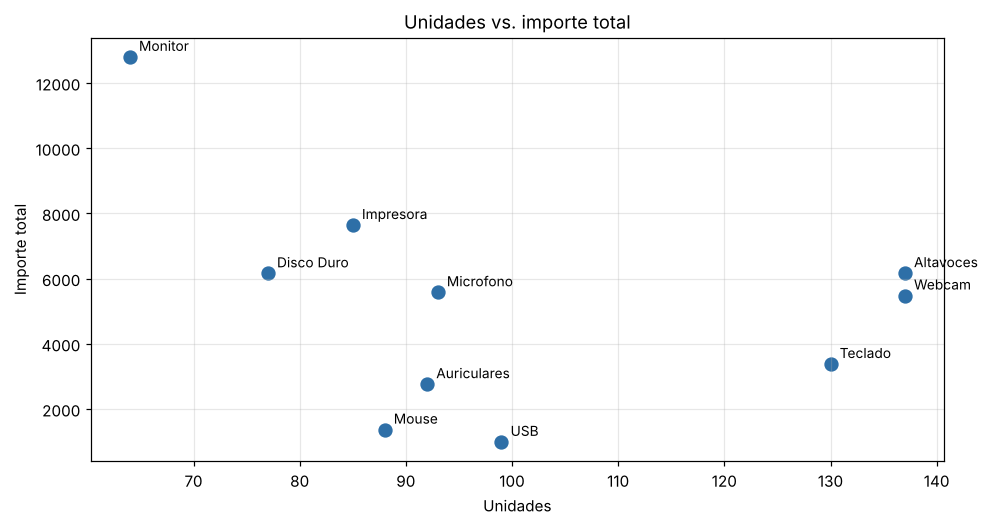

In [0]:
import matplotlib.pyplot as plt

pdf = spark.table("analitica.data.v_ventas_por_producto").toPandas()

fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(pdf["unidades"], pdf["importe_total"], s=70, color="#2E6FA7")
for _, r in pdf.iterrows():
    ax.annotate(r["producto"], (r["unidades"], r["importe_total"]),
                textcoords="offset points", xytext=(6, 4), fontsize=9)
ax.set_title("Unidades vs. importe total")
ax.set_xlabel("Unidades")
ax.set_ylabel("Importe total")
ax.grid(alpha=0.3)
plt.show()

**SOLUCIÓN PREGUNTAS**

**Si el CSV está en un volumen, ¿qué falta para que otro notebook consulte una tabla persistente?**

Falta registrar una tabla en el catálogo. Un volumen solo guarda archivos. Mientras no exista una tabla, el otro notebook tendría que volver a leer el CSV, y un DataFrame o una vista temporal solo vive en la sesión que lo creó.


**Si una unión duplica el importe total, ¿qué comprobación haríamos sobre las llaves?**

Que la llave sea única en la tabla del lado “uno” (por ejemplo, la dimensión). Si un mismo id aparece dos veces, cada venta se multiplica, conviene revisar tres cosas: que la unión use todas las columnas de la llave compuesta, que los tipos y formatos coincidan (espacios, mayúsculas, '01' frente a 1) y que compares COUNT(*) y SUM(importe) antes y después del join.


****Si** una celda define un filtro, ¿significa que Spark ya calculó todo el resultado?**

No precisamente, ya que Spark usa evaluación sencilla. filter, select y join son transformaciones que solo construyen un plan. El cálculo ocurre cuando se ejecuta una acción como display(), show(), count(), collect() o una escritura (write, saveAsTable). Por eso un error en los datos puede aparecer recién en la acción y no en la celda del filtro.

**Si una persona tiene SELECT sobre una tabla, ¿qué otros permisos de uso necesita?**

USE CATALOG sobre el catálogo.
USE SCHEMA sobre el esquema.
Acceso a un cómputo: permiso para usar el SQL warehouse o el clúster

**Si el historial de la tabla muestra una versión antigua, ¿basta para garantizar su recuperación?**

No. DESCRIBE HISTORY muestra los metadatos del log, pero los archivos de datos de esa versión pueden haberse borrado:

VACUUM elimina los archivos que ya no se usan y que superan la retención, que por defecto son 7 días (delta.deletedFileRetentionDuration).
El log también tiene su propia retención (delta.logRetentionDuration, 30 días por defecto).


**Si repetimos un append con el mismo archivo, ¿qué puede pasar con las ventas?**

Se duplican. mode("append") no recuerda qué archivos ya cargó, así que vuelve a insertar las mismas filas y los totales aparecen inflados. Hay tres formas de evitarlo:

COPY INTO: es idempotente y omite los archivos que ya cargó.
MERGE INTO por la llave de venta: inserta solo lo nuevo y actualiza lo existente.
Auto Loader: con checkpoint, lleva el control de los archivos procesados.

Si ya ocurrió, puedes detectarlo con un GROUP BY sobre la llave de venta (HAVING COUNT(*) > 1) y corregirlo con RESTORE a la versión anterior al append.